<a href="https://colab.research.google.com/github/farai678/boston-311-ai-service-planning./blob/main/IE7615_Project_Two_Milestone_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip -q install "transformers==4.57.6" pyarrow pandas pillow matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [3]:
from io import BytesIO
from pathlib import Path
from random import Random
from textwrap import fill

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
import torch
import transformers
from huggingface_hub import hf_hub_download
from IPython.display import display
from PIL import Image, UnidentifiedImageError
from torch import nn
from transformers import CLIPImageProcessor, CLIPVisionModelWithProjection
from transformers import GPT2Config, GPT2LMHeadModel, GPT2TokenizerFast

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

output_dir = Path("milestone_outputs")
output_dir.mkdir(exist_ok=True)

print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}")
print(f"Transformers: {transformers.__version__}")

Device: cuda
PyTorch: 2.14.1+cu130
Transformers: 4.57.6


In [4]:
dataset_path = hf_hub_download(
    repo_id="lmms-lab-encoder/COCO-Caption2017",
    repo_type="dataset",
    filename="data/val-00000-of-00002.parquet",
    revision="3bdd5827e243cc3084ac69a1111e69c3ab9193ff",
)
dataset = pq.ParquetFile(dataset_path)

images = {}
filenames = {}
references = {}
target_images = 220
references_per_image = 5

for batch in dataset.iter_batches(
    batch_size=64,
    columns=["file_name", "image", "answer"],
):
    for row in batch.to_pylist():
        filename = row["file_name"]
        image_id = int(Path(filename).stem)

        if image_id in images:
            continue

        captions = []
        seen = set()

        for text in row["answer"] or []:
            caption = " ".join((text or "").split())

            if caption and caption.casefold() not in seen:
                captions.append(caption)
                seen.add(caption.casefold())

        image_bytes = (row["image"] or {}).get("bytes")

        if len(captions) < references_per_image or not image_bytes:
            continue

        try:
            with Image.open(BytesIO(image_bytes)) as image:
                rgb_image = image.convert("RGB")
        except (UnidentifiedImageError, OSError):
            continue

        images[image_id] = rgb_image
        filenames[image_id] = filename
        references[image_id] = captions[:references_per_image]

        if len(images) == target_images:
            break

    if len(images) == target_images:
        break

assert len(images) == target_images

image_ids = sorted(images)
Random(42).shuffle(image_ids)

split_ids = {
    "train": image_ids[:176],
    "validation": image_ids[176:198],
    "test": image_ids[198:],
}

pairs = pd.DataFrame(
    [
        {
            "image_id": image_id,
            "filename": filenames[image_id],
            "split": split,
            "reference_caption": caption,
        }
        for split, ids in split_ids.items()
        for image_id in ids
        for caption in references[image_id]
    ]
)

assert len(pairs) == target_images * references_per_image
assert pairs.groupby("image_id")["split"].nunique().eq(1).all()

summary = pairs.groupby("split").agg(
    images=("image_id", "nunique"),
    pairs=("image_id", "size"),
)

display(summary)
print(f"Total images: {len(images)}")
print(f"Total image-caption pairs: {len(pairs)}")
display(pairs.head())

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


data/val-00000-of-00002.parquet:   0%|          | 0.00/424M [00:00<?, ?B/s]

,images,pairs
split,,
test,22,110
train,176,880
validation,22,110


Total images: 220
Total image-caption pairs: 1100


,image_id,filename,split,reference_caption
0,515266,000000515266.jpg,train,A white truck parked next to a white trailer.
1,515266,000000515266.jpg,train,"A large truck is parked beside an old, wooden ..."
2,515266,000000515266.jpg,train,A truck and trailer sit behind a long bench.
3,515266,000000515266.jpg,train,an image of a truck with a side trailer
4,515266,000000515266.jpg,train,A wooden bench with an old tire sitting on it.


In [5]:
gpt2_id = "openai-community/gpt2"
tokenizer = GPT2TokenizerFast.from_pretrained(gpt2_id)

tokens = tokenizer(
    pairs["reference_caption"].tolist(),
    add_special_tokens=False,
)

pairs["gpt2_token_ids"] = tokens["input_ids"]
pairs["token_count"] = pairs["gpt2_token_ids"].map(len)

assert pairs["token_count"].gt(0).all()

pairs.to_json(
    output_dir / "coco_caption_pairs.jsonl",
    orient="records",
    lines=True,
)

display(
    pairs[["reference_caption", "gpt2_token_ids", "token_count"]].head(3)
)

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

,reference_caption,gpt2_token_ids,token_count
0,A white truck parked next to a white trailer.,"[32, 2330, 7779, 19584, 1306, 284, 257, 2330, ...",10
1,"A large truck is parked beside an old, wooden ...","[32, 1588, 7779, 318, 19584, 13970, 281, 1468,...",12
2,A truck and trailer sit behind a long bench.,"[32, 7779, 290, 12268, 1650, 2157, 257, 890, 7...",10


In [6]:
clip_id = "openai/clip-vit-base-patch32"
clip_revision = "b97b0100e55e367c057773c2a614676470b0d575"

clip_processor = CLIPImageProcessor.from_pretrained(
    clip_id,
    revision=clip_revision,
)

clip_model = CLIPVisionModelWithProjection.from_pretrained(
    clip_id,
    revision=clip_revision,
    use_safetensors=True,
).to(device).eval()

embedding_batches = []
batch_size = 16

with torch.inference_mode():
    for start in range(0, len(image_ids), batch_size):
        batch_ids = image_ids[start:start + batch_size]

        inputs = clip_processor(
            images=[images[image_id] for image_id in batch_ids],
            return_tensors="pt",
        ).to(device)

        batch_embeddings = clip_model(**inputs).image_embeds.cpu()
        embedding_batches.append(batch_embeddings)

embeddings = torch.cat(embedding_batches)

assert embeddings.shape == (target_images, 512)
assert torch.isfinite(embeddings).all()

torch.save(
    {"image_ids": torch.tensor(image_ids), "embeddings": embeddings},
    output_dir / "clip_image_embeddings.pt",
)

print("CLIP embedding tensor shape", tuple(embeddings.shape))

del clip_model

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

CLIP embedding tensor shape (220, 512)


In [7]:
checkpoint_path = hf_hub_download(
    repo_id="akhaliq/CLIP-prefix-captioning-COCO-weights",
    filename="coco_weights.pt",
    revision="cecb9cd3b42d170f82d4fa5ff22dcd1a25941677",
)

weights = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

prefix_length = 10
gpt2_config = GPT2Config.from_pretrained(gpt2_id)
gpt2 = GPT2LMHeadModel(gpt2_config)

projection_size = prefix_length * gpt2_config.n_embd
projection = nn.Sequential(
    nn.Linear(512, projection_size // 2),
    nn.Tanh(),
    nn.Linear(projection_size // 2, projection_size),
)

gpt2_weights = {
    name.removeprefix("gpt."): weight
    for name, weight in weights.items()
    if name.startswith("gpt.")
    and not name.endswith((".attn.bias", ".attn.masked_bias"))
}

projection_weights = {
    name.removeprefix("clip_project.model."): weight
    for name, weight in weights.items()
    if name.startswith("clip_project.model.")
}

gpt2.load_state_dict(gpt2_weights)
projection.load_state_dict(projection_weights)

gpt2 = gpt2.to(device).eval()
projection = projection.to(device).eval()

del weights, gpt2_weights, projection_weights

print("ClipCap checkpoint loaded.")

coco_weights.pt:   0%|          | 0.00/636M [00:00<?, ?B/s]

ClipCap checkpoint loaded.


In [8]:
period_id = tokenizer.encode(".", add_special_tokens=False)[0]
embedding_rows = {
    image_id: index
    for index, image_id in enumerate(image_ids)
}
sample_ids = split_ids["test"][:5]
results = []

with torch.inference_mode():
    for image_id in sample_ids:
        image_vector = embeddings[embedding_rows[image_id]].unsqueeze(0).to(device)

        prefix = projection(image_vector).reshape(
            1,
            prefix_length,
            gpt2_config.n_embd,
        )

        generated = gpt2.generate(
            inputs_embeds=prefix,
            attention_mask=torch.ones(
                (1, prefix_length),
                dtype=torch.long,
                device=device,
            ),
            max_new_tokens=35,
            do_sample=False,
            eos_token_id=[period_id, tokenizer.eos_token_id],
            pad_token_id=tokenizer.eos_token_id,
        )

        caption = tokenizer.decode(
            generated[0],
            skip_special_tokens=True,
        ).strip()

        results.append(
            {
                "image_id": image_id,
                "filename": filenames[image_id],
                "reference_caption": references[image_id][0],
                "generated_caption": caption,
            }
        )

assert len(results) == 5 and all(row["generated_caption"] for row in results)

results_df = pd.DataFrame(results)
results_df.to_csv(
    output_dir / "five_caption_test_runs.csv",
    index=False,
)

display(results_df)

,image_id,filename,reference_caption,generated_caption
0,308799,000000308799.jpg,A doorway into a clean wood floored kitchen.,A kitchen with a black counter top and black c...
1,147518,000000147518.jpg,A bathroom that has magazine rack and small ca...,"A bathroom with a toilet, sink, and mirror."
2,139099,000000139099.jpg,A street scene with a person on a motorcycle.,A man on a motor bike talks on a cell phone.
3,53505,000000053505.jpg,A toilet sitting underneath a medicine cabinet...,A bathroom with a toilet and a shower.
4,17379,000000017379.jpg,a flat screen TV embedded in a restroom mirror.,A television is mounted on a wall in a bathroom.


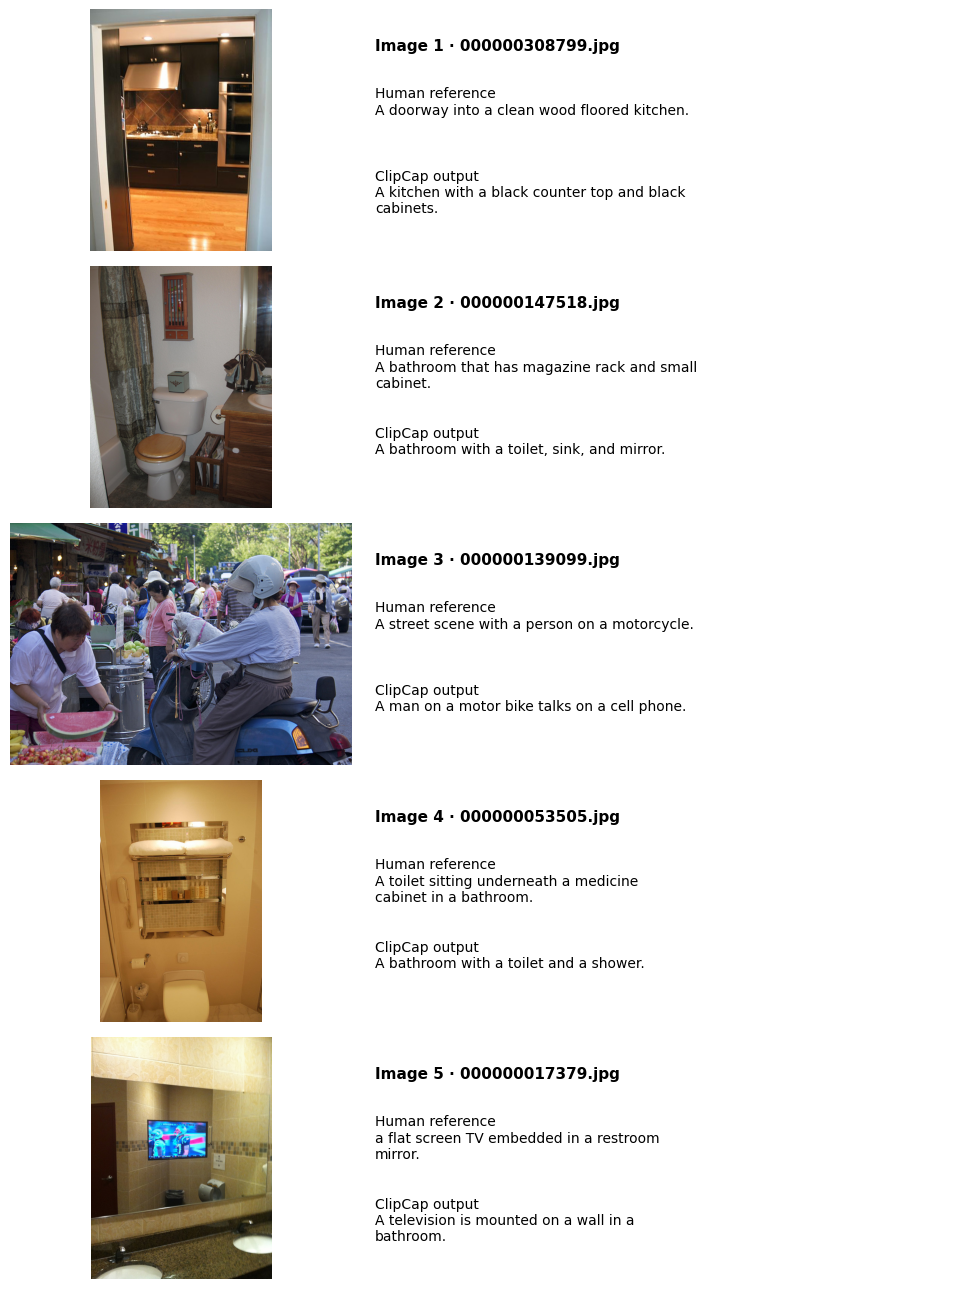

In [9]:
figure, panels = plt.subplots(
    len(results),
    2,
    figsize=(10, 13),
    width_ratios=[1, 1.4],
)

for number, (row, (image_panel, caption_panel)) in enumerate(
    zip(results, panels),
    start=1,
):
    image_panel.imshow(images[row["image_id"]])
    image_panel.set_axis_off()
    caption_panel.set_axis_off()

    caption_panel.text(
        0, 0.88,
        f'Image {number} · {row["filename"]}',
        fontsize=11,
        fontweight="bold",
        va="top",
    )
    caption_panel.text(
        0, 0.68,
        "Human reference\n" + fill(row["reference_caption"], 45),
        fontsize=10,
        va="top",
    )
    caption_panel.text(
        0, 0.34,
        "ClipCap output\n" + fill(row["generated_caption"], 45),
        fontsize=10,
        va="top",
    )

figure.tight_layout()
figure.savefig(
    output_dir / "five_caption_test_runs.png",
    dpi=170,
    bbox_inches="tight",
)
plt.show()

In [10]:
from pathlib import Path

from transformers import set_seed

milestone2_dir = Path("milestone2_outputs")
milestone2_dir.mkdir(exist_ok=True)

sample_ids_m2 = split_ids["test"][:5]
embedding_row = {image_id: i for i, image_id in enumerate(image_ids)}
eos_id = tokenizer.eos_token_id
period_id = tokenizer.encode(".", add_special_tokens=False)[0]


@torch.inference_mode()
def generate_caption(image_id, **decoding):
    projection.eval()
    gpt2.eval()

    vector = embeddings[embedding_row[image_id]].unsqueeze(0).to(device)
    prefix = projection(vector).reshape(1, prefix_length, gpt2.config.n_embd)
    prefix_mask = torch.ones((1, prefix_length), dtype=torch.long, device=device)

    output = gpt2.generate(
        inputs_embeds=prefix,
        attention_mask=prefix_mask,
        max_new_tokens=35,
        eos_token_id=[period_id, eos_id],
        pad_token_id=eos_id,
        **decoding,
    )
    return tokenizer.decode(output[0], skip_special_tokens=True).strip()


baseline = pd.DataFrame([
    {
        "image_id": image_id,
        "filename": filenames[image_id],
        "reference_caption": references[image_id][0],
        "pretrained_greedy": generate_caption(
            image_id, do_sample=False, num_beams=1
        ),
    }
    for image_id in sample_ids_m2
])

baseline.to_csv(milestone2_dir / "baseline_captions.csv", index=False)

with pd.option_context("display.max_colwidth", None):
    display(baseline)

,image_id,filename,reference_caption,pretrained_greedy
0,308799,000000308799.jpg,A doorway into a clean wood floored kitchen.,A kitchen with a black counter top and black cabinets.
1,147518,000000147518.jpg,A bathroom that has magazine rack and small cabinet.,"A bathroom with a toilet, sink, and mirror."
2,139099,000000139099.jpg,A street scene with a person on a motorcycle.,A man on a motor bike talks on a cell phone.
3,53505,000000053505.jpg,A toilet sitting underneath a medicine cabinet in a bathroom.,A bathroom with a toilet and a shower.
4,17379,000000017379.jpg,a flat screen TV embedded in a restroom mirror.,A television is mounted on a wall in a bathroom.


In [11]:
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

set_seed(42)
gpt2.requires_grad_(False)
gpt2.eval()
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

batch_size = 8
epochs = 2
learning_rate = 1e-5
max_caption_tokens = 48


def collate_caption_batch(rows):
    image_batch = torch.stack([
        embeddings[embedding_row[image_id]]
        for image_id, _ in rows
    ])
    caption_ids = [
        token_ids[:max_caption_tokens - 1] + [eos_id]
        for _, token_ids in rows
    ]
    text_batch = tokenizer.pad(
        {"input_ids": caption_ids},
        padding=True,
        return_tensors="pt",
    )
    return image_batch, text_batch["input_ids"], text_batch["attention_mask"]


loaders = {}

for split in ("train", "validation"):
    rows = list(
        pairs.loc[pairs["split"].eq(split), ["image_id", "gpt2_token_ids"]]
        .itertuples(index=False, name=None)
    )
    loaders[split] = DataLoader(
        rows,
        batch_size=batch_size,
        shuffle=(split == "train"),
        collate_fn=collate_caption_batch,
    )

optimizer = torch.optim.AdamW(projection.parameters(), lr=learning_rate)


def run_epoch(loader, training, description):
    projection.train(training)
    total_loss = 0.0
    total_tokens = 0

    with torch.set_grad_enabled(training):
        for image_batch, input_ids, caption_mask in tqdm(loader, desc=description):
            image_batch = image_batch.to(device)
            input_ids = input_ids.to(device)
            caption_mask = caption_mask.to(device)

            prefix = projection(image_batch).reshape(
                image_batch.shape[0], prefix_length, gpt2.config.n_embd
            )
            caption_embeddings = gpt2.get_input_embeddings()(input_ids)
            inputs = torch.cat((prefix, caption_embeddings), dim=1)

            prefix_mask = caption_mask.new_ones((input_ids.shape[0], prefix_length))
            attention_mask = torch.cat((prefix_mask, caption_mask), dim=1)
            caption_labels = input_ids.masked_fill(caption_mask == 0, -100)
            prefix_labels = torch.full_like(prefix_mask, -100)
            labels = torch.cat((prefix_labels, caption_labels), dim=1)

            if training:
                optimizer.zero_grad(set_to_none=True)

            loss = gpt2(
                inputs_embeds=inputs,
                attention_mask=attention_mask,
                labels=labels,
                use_cache=False,
            ).loss

            if training:
                loss.backward()
                optimizer.step()

            token_count = int(caption_mask.sum().item())
            total_loss += loss.detach().item() * token_count
            total_tokens += token_count

    return total_loss / total_tokens


initial_val_loss = run_epoch(loaders["validation"], False, "Pretrained validation")
training_rows = [
    {"epoch": 0, "train_loss": None, "validation_loss": initial_val_loss}
]

for epoch in range(1, epochs + 1):
    train_loss = run_epoch(loaders["train"], True, f"Epoch {epoch} training")
    val_loss = run_epoch(loaders["validation"], False, f"Epoch {epoch} validation")

    training_rows.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": val_loss,
    })
    training_log = pd.DataFrame(training_rows)
    training_log.to_csv(milestone2_dir / "training_log.csv", index=False)
    print(f"Epoch {epoch} | Train loss {train_loss:.4f} | Validation loss {val_loss:.4f}")

torch.save(projection.state_dict(), milestone2_dir / "trained_projection.pt")
display(training_log.round(4))

Pretrained validation:   0%|          | 0/14 [00:00<?, ?it/s]

You're using a GPT2TokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.
`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Epoch 1 training:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 1 validation:   0%|          | 0/14 [00:00<?, ?it/s]

Epoch 1 | Train loss 3.0798 | Validation loss 3.1363


Epoch 2 training:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 2 validation:   0%|          | 0/14 [00:00<?, ?it/s]

Epoch 2 | Train loss 2.7857 | Validation loss 2.9306


,epoch,train_loss,validation_loss
0,0,NaN,3.2513
1,1,3.0798,3.1363
2,2,2.7857,2.9306


In [12]:
decoders = {
    "greedy": {"do_sample": False, "num_beams": 1},
    "beam_search": {
        "do_sample": False,
        "num_beams": 3,
        "early_stopping": True,
    },
    "nucleus_sampling": {
        "do_sample": True,
        "num_beams": 1,
        "top_p": 0.9,
        "top_k": 0,
        "temperature": 1.0,
    },
}

set_seed(42)
comparison = baseline.copy()

for method, settings in decoders.items():
    comparison[method] = [
        generate_caption(image_id, **settings)
        for image_id in sample_ids_m2
    ]

comparison.to_csv(milestone2_dir / "decoding_comparison.csv", index=False)

with pd.option_context("display.max_colwidth", None):
    display(comparison)

,image_id,filename,reference_caption,pretrained_greedy,greedy,beam_search,nucleus_sampling
0,308799,000000308799.jpg,A doorway into a clean wood floored kitchen.,A kitchen with a black counter top and black cabinets.,A kitchen with a black counter top and black cabinets.,A kitchen with black counter tops and a black refrigerator.,A clean kitchen that is ready for us to use.
1,147518,000000147518.jpg,A bathroom that has magazine rack and small cabinet.,"A bathroom with a toilet, sink, and mirror.","A bathroom with a toilet, sink, and mirror.","A bathroom with a toilet, sink, and mirror.",A bathroom with a pink and tan striped shower curtain.
2,139099,000000139099.jpg,A street scene with a person on a motorcycle.,A man on a motor bike talks on a cell phone.,A man on a motor bike talking on a cell phone.,A man on a motorcycle talking on a cell phone.,A group of people on motor bikes and one person on scooter stand at an outdoor food market.
3,53505,000000053505.jpg,A toilet sitting underneath a medicine cabinet in a bathroom.,A bathroom with a toilet and a shower.,A bathroom with a toilet and a shower.,A bathroom with a white toilet and a white bath tub.,"A bathroom with a shower, a sink, and a medicine cabinet."
4,17379,000000017379.jpg,a flat screen TV embedded in a restroom mirror.,A television is mounted on a wall in a bathroom.,A television is mounted on a wall above a toilet.,A flat screen TV mounted on a wall in a bathroom.,A picture of Monica Lewandowski on the television in a bathroom.


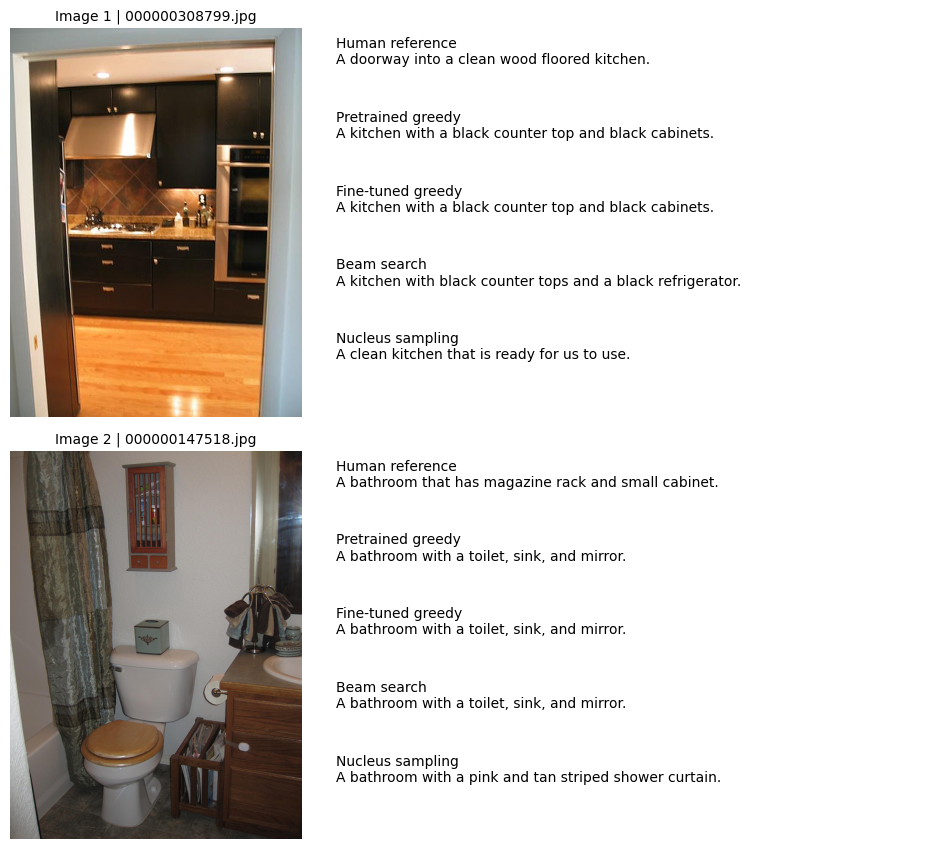

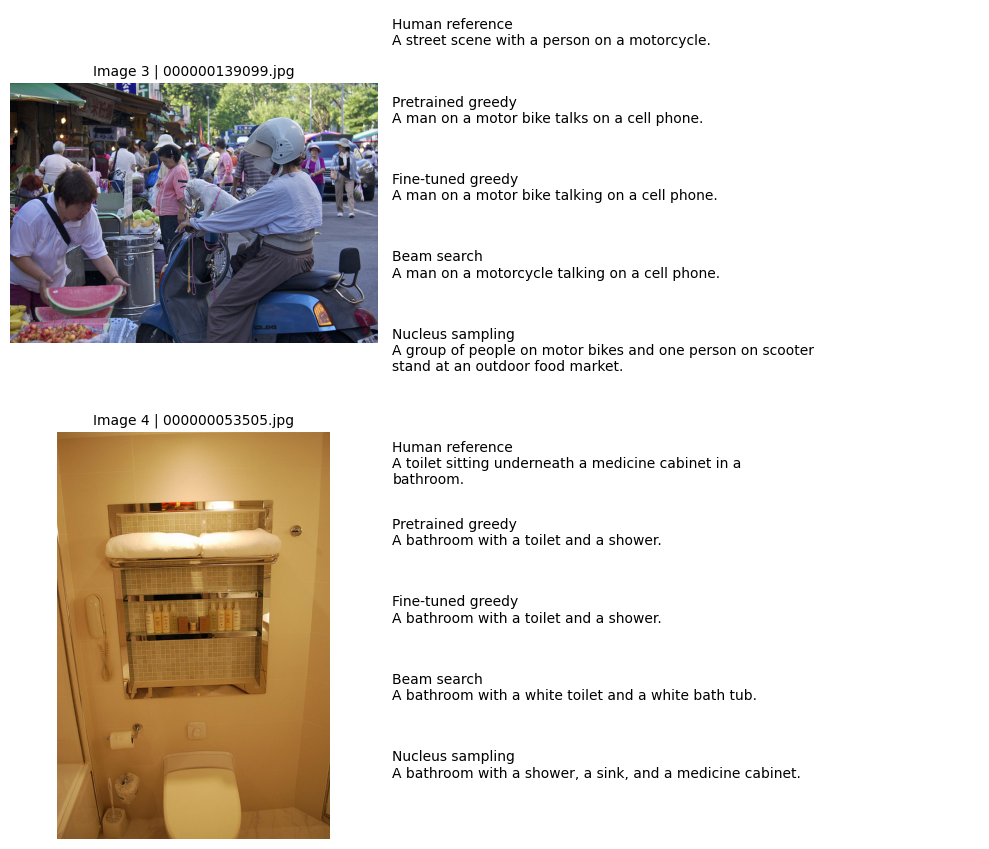

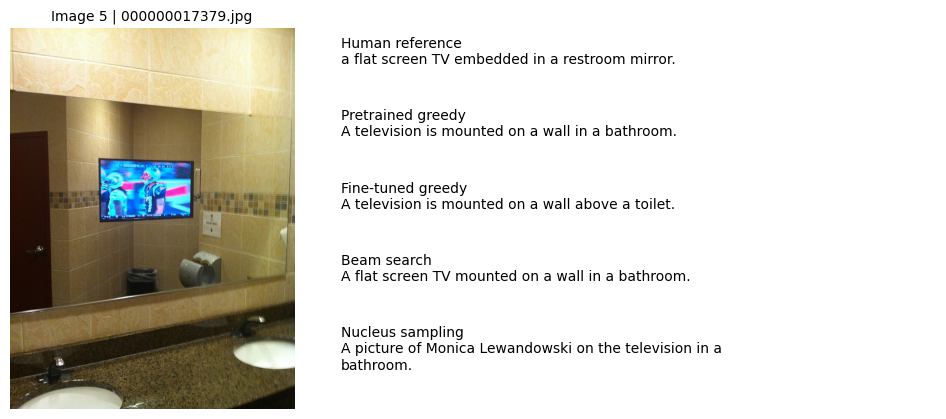

In [13]:
caption_fields = [
    ("Human reference", "reference_caption"),
    ("Pretrained greedy", "pretrained_greedy"),
    ("Fine-tuned greedy", "greedy"),
    ("Beam search", "beam_search"),
    ("Nucleus sampling", "nucleus_sampling"),
]

sample_records = comparison.to_dict("records")

for page_number, start in enumerate(range(0, len(sample_records), 2), start=1):
    page_rows = sample_records[start:start + 2]

    figure, panels = plt.subplots(
        len(page_rows), 2,
        figsize=(10, 4.3 * len(page_rows)),
        width_ratios=[1, 1.6],
        squeeze=False,
    )

    for offset, (row, (image_ax, text_ax)) in enumerate(zip(page_rows, panels)):
        image_ax.imshow(images[row["image_id"]])
        image_ax.set_title(f'Image {start + offset + 1} | {row["filename"]}', fontsize=10)
        image_ax.axis("off")
        text_ax.axis("off")

        for i, (label, column) in enumerate(caption_fields):
            text_ax.text(
                0, 0.98 - i * 0.19,
                label + "\n" + fill(row[column], width=60),
                fontsize=10,
                va="top",
            )

    figure.tight_layout()
    figure.savefig(milestone2_dir / f"caption_samples_{page_number}.png", dpi=160)
    plt.show()
    plt.close(figure)